<a href="https://colab.research.google.com/github/ndim-labs/p1-gpt-from-scratch/blob/main/1.0-preparation/gpt_dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decoding Language Models
### Phase 1 · Foundations — Session 1.0: Preparation · *Building a GPT from scratch*

**nDimensions.AI** · course repo [ndim-labs/p1-gpt-from-scratch](https://github.com/ndim-labs/p1-gpt-from-scratch)

---

**About this notebook.** This session follows Andrej Karpathy's **[Neural Networks: Zero to Hero](https://karpathy.ai/zero-to-hero.html)** series, specifically the lecture [“Let's build GPT: from scratch, in code, spelled out”](https://www.youtube.com/watch?v=kCc8FmEb1nY). The code is Karpathy's companion notebook; the **plain-English explanations, paper references and charts** were added by nDimensions.AI for this course.

**How to use it**
1. **File → Save a copy in Drive**, then **Runtime → Change runtime type → T4 GPU**.
2. Run the cells top to bottom. Read each explanation *before* running the cell under it.
3. Keep the paper open alongside: [Attention Is All You Need](https://arxiv.org/html/1706.03762v7) (§3 is the part we use).

| Part | What you'll learn |
|---|---|
| Steps 1–7 | Data, tokens, batches |
| Steps 8–10 | The simplest model (bigram) and training, with a loss chart |
| The mathematical trick | How averaging the past turns into self-attention (paper §3.2), with heatmaps |
| Full code | The complete GPT, trained, with a training vs validation chart |
| Bonus | An interactive text generator, then save the model. It powers our [Shakespeare GPT chatbot](https://github.com/ndim-labs/shakespeare_gpt_v1) |

**Where this fits in the course:** 1.0 Preparation → 1.1a From data to self-attention → 1.1b The full Transformer → 1.2 Shaer-GPT (our own code, Arabic poetry) → 1.3 Fine-tuning: full vs LoRA vs QLoRA → Gate 1.

## Step 1 · Get the data
A language model learns by reading lots of text. Ours reads **Tiny Shakespeare**: about 1 million characters of his plays in one file.

In [1]:
# We always start with a dataset to train on. Let's download the tiny shakespeare dataset
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-17 17:27:36--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.007s  

2026-10-17 17:27:36 (159 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [2]:
# read it in to inspect it
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [3]:
print("length of dataset in characters: ", len(text))

length of dataset in characters:  1115394


In [4]:
# let's look at the first 1000 characters
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



## Step 2 · The vocabulary
The model can only output symbols it knows. Here every **character** is a symbol, so the vocabulary is the set of unique characters: 65 of them (letters, punctuation, space, newline).

*Real models use bigger pieces called tokens: GPT-4's vocabulary has about 100,000 tokens. Characters keep things simple.*

In [5]:
# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


## Step 3 · Tokenizer: text ↔ numbers
Neural networks only understand numbers, so we give each character an ID:
- `encode`: text → list of numbers (`"hii"` → `[46, 47, 47]`)
- `decode`: numbers → text

**Check:** `decode(encode(x))` must give back exactly `x`.

In [6]:
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

print(encode("hii there"))
print(decode(encode("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


## Step 4 · The whole book as one long list of numbers
We encode the entire text into one PyTorch **tensor** (a fast array that can live on the GPU). This is all the model ever sees: a stream of integers.

In [7]:
# let's now encode the entire text dataset and store it into a torch.Tensor
import torch # we use PyTorch: https://pytorch.org
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000]) # the 1000 characters we looked at earier will to the GPT look like this

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 15, 39, 47, 59, 57,  1, 25, 39, 56, 41,
      

## Step 5 · Train / validation split
We hide the last 10% of the text from the model during training.
- **Training data (90%):** what the model learns from.
- **Validation data (10%):** a test on text it has *never seen*.

If training loss goes down but validation loss goes up, the model is **memorizing** rather than **learning**. That's called *overfitting*.

In [8]:
# Let's now split up the data into train and validation sets
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

## Step 6 · Context: how far back the model looks
We never feed the whole book at once. We feed chunks of `block_size` characters (here 8).

In [9]:
block_size = 8
train_data[:block_size+1]

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])

In [10]:
x = train_data[:block_size]
y = train_data[1:block_size+1]


In [11]:
print(x)

tensor([18, 47, 56, 57, 58,  1, 15, 47])


In [12]:
print(y)

tensor([47, 56, 57, 58,  1, 15, 47, 58])


### One chunk = many training examples
A chunk of 9 characters hides **8 lessons**: given 1 character, predict the 2nd; given 2, predict the 3rd; and so on.
That's why `y` is just `x` **shifted by one**: `y[t]` is the correct "next character" for everything up to `x[t]`.

In [13]:
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


## Step 7 · Batches: many chunks in parallel
GPUs are fastest when they do lots of work at once, so we grab `batch_size` random chunks together.
The result is a grid of shape **(B, T)** = (batch, time) = (4 chunks, 8 characters each).

In [14]:
torch.manual_seed(1337)
batch_size = 4 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?



In [15]:
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y


In [16]:
print(train_data.size())
print(train_data)

torch.Size([1003854])
tensor([18, 47, 56,  ..., 43, 56, 43])


In [17]:

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')


inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])
----


Every cell of the (4 × 8) grid is one "given this context → predict that character" lesson: **32 lessons per batch.**

In [18]:

for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

when input is [24] the target: 43
when input is [24, 43] the target: 58
when input is [24, 43, 58] the target: 5
when input is [24, 43, 58, 5] the target: 57
when input is [24, 43, 58, 5, 57] the target: 1
when input is [24, 43, 58, 5, 57, 1] the target: 46
when input is [24, 43, 58, 5, 57, 1, 46] the target: 43
when input is [24, 43, 58, 5, 57, 1, 46, 43] the target: 39
when input is [44] the target: 53
when input is [44, 53] the target: 56
when input is [44, 53, 56] the target: 1
when input is [44, 53, 56, 1] the target: 58
when input is [44, 53, 56, 1, 58] the target: 46
when input is [44, 53, 56, 1, 58, 46] the target: 39
when input is [44, 53, 56, 1, 58, 46, 39] the target: 58
when input is [44, 53, 56, 1, 58, 46, 39, 58] the target: 1
when input is [52] the target: 58
when input is [52, 58] the target: 1
when input is [52, 58, 1] the target: 58
when input is [52, 58, 1, 58] the target: 46
when input is [52, 58, 1, 58, 46] the target: 39
when input is [52, 58, 1, 58, 46, 39] the t

In [19]:
print(xb) # our input to the transformer

tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])


## Step 8 · The simplest language model: bigram
The bigram model predicts the next character by looking at **only the current one**: no memory and no context.
It's just a lookup table: row = current character, columns = scores for each possible next character.

- **Logits:** raw scores for every possible next character (65 numbers)
- **Cross-entropy loss:** how surprised the model is by the true next character. Lower is better.
- **generate():** repeatedly predict → pick a character at random (weighted by probability) → append → repeat

In [20]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):

        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx) # (B,T,C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx



In [21]:
vocab_size

65

In [22]:
print(xb.size())
print(xb)

torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])


In [23]:
print(yb.size())
print(yb)

torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])


### Sanity check: the loss before any training
A model that guesses uniformly among 65 characters has a loss of **ln(65) ≈ 4.17**.
You'll see a bit more (about 4.6–4.9) because random starting weights aren't perfectly uniform. That's normal. If it's *far* off (say 10 or 0.5), something is broken. This one check catches many bugs.

In [24]:
m = BigramLanguageModel(vocab_size)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)


torch.Size([32, 65])
tensor(4.8786, grad_fn=<NllLossBackward0>)


### The untrained model writes nonsense
Random weights → random characters. Remember this output to compare after training.

In [25]:
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=100)[0].tolist()))



SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


## Step 9 · The optimizer
**AdamW** is the algorithm that nudges every weight a little after each batch, in the direction that lowers the loss. `lr` (learning rate) is the step size.

In [26]:
# create a PyTorch optimizer
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)
optimizer

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.01
)

## Step 10 · Train the bigram model, and record the loss
Each step: grab a batch → compute the loss → compute gradients (`backward`) → update the weights (`step`).
We now **record** the training loss at every step, and check the **validation** loss every 500 steps, so we can plot them.

In [27]:
# Train the bigram model and record the loss so we can plot it
batch_size = 32
max_steps = 10000  # more steps than the original 100, so we see the full curve
eval_every = 500
train_losses, val_points = [], []

@torch.no_grad()
def bigram_val_loss(iters=100):
    m.eval()
    out = torch.zeros(iters)
    for k in range(iters):
        xv, yv = get_batch('val')
        _, l = m(xv, yv)
        out[k] = l.item()
    m.train()
    return out.mean().item()

for step in range(max_steps):
    xb, yb = get_batch('train')           # 1. sample a batch
    logits, loss = m(xb, yb)              # 2. forward pass: how wrong are we?
    optimizer.zero_grad(set_to_none=True)
    loss.backward()                       # 3. gradients: which way to nudge each weight
    optimizer.step()                      # 4. nudge the weights
    train_losses.append(loss.item())
    if step % eval_every == 0 or step == max_steps - 1:
        val_points.append((step, bigram_val_loss()))

print(f"final train loss {train_losses[-1]:.3f} | final val loss {val_points[-1][1]:.3f}")

final train loss 2.445 | final val loss 2.481


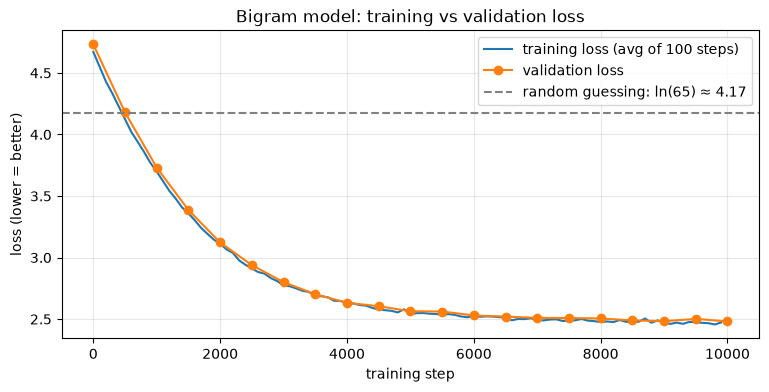

In [28]:
# Plot: is the bigram model learning?
import math
import matplotlib.pyplot as plt

chunk = 100  # average the noisy per-step loss over 100 steps
smooth = torch.tensor(train_losses[: len(train_losses) // chunk * chunk]).view(-1, chunk).mean(1)
val_steps, val_losses = zip(*val_points)

plt.figure(figsize=(9, 4))
plt.plot(range(0, len(smooth) * chunk, chunk), smooth, label="training loss (avg of 100 steps)")
plt.plot(val_steps, val_losses, "o-", label="validation loss")
plt.axhline(math.log(vocab_size), ls="--", c="gray", label=f"random guessing: ln({vocab_size}) ≈ {math.log(vocab_size):.2f}")
plt.xlabel("training step"); plt.ylabel("loss (lower = better)")
plt.title("Bigram model: training vs validation loss"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**How to read this chart**
- Both curves fall fast from ~4.2 (random guessing), then **flatten around 2.5**. That's the best a model with one character of memory can do.
- Training and validation stay **close together**: the model isn't memorizing, it's just too simple. More training won't help; a better model (attention) will.

In [29]:
print(xb)

tensor([[ 1, 41, 59, 50, 50,  5, 42,  1],
        [53, 52, 48, 59, 56, 43, 42,  1],
        [46,  1, 39,  1, 49, 47, 57, 57],
        [35, 43, 56, 43,  1, 52, 43, 60],
        [51, 47, 58,  1, 51, 43,  1, 44],
        [43,  1, 46, 47, 57,  1, 57, 47],
        [42, 43, 52, 57,  1, 58, 46, 43],
        [52,  1, 42, 53,  1, 21,  1, 57],
        [49,  1, 58, 46, 43, 56, 43,  1],
        [43, 56, 57,  1, 42, 56, 63, 11],
        [33, 23, 17,  1, 34, 21, 26, 15],
        [53,  1, 51, 63,  1, 56, 43, 57],
        [ 1, 51, 63,  1, 46, 43, 39, 56],
        [ 1, 59, 54, 53, 52,  1,  5, 57],
        [42,  0, 24, 43, 57, 57,  1, 47],
        [47, 58,  1, 47, 57,  1, 39,  0],
        [49,  1, 58, 46, 43,  1, 42, 39],
        [ 1, 47, 52,  1, 58, 46, 43,  1],
        [39, 58,  1, 61, 43,  1, 47, 52],
        [53, 59, 58, 46, 57,  6,  0, 13],
        [ 1, 61, 46, 53, 57, 43,  1, 52],
        [39, 47, 52,  0, 25, 63,  1, 61],
        [52, 58, 10,  0, 21,  1, 42, 53],
        [47, 52,  6,  1, 41, 53, 5

In [30]:
print(yb)

tensor([[41, 59, 50, 50,  5, 42,  1, 57],
        [52, 48, 59, 56, 43, 42,  1, 47],
        [ 1, 39,  1, 49, 47, 57, 57,  1],
        [43, 56, 43,  1, 52, 43, 60, 43],
        [47, 58,  1, 51, 43,  1, 44, 53],
        [ 1, 46, 47, 57,  1, 57, 47, 57],
        [43, 52, 57,  1, 58, 46, 43, 51],
        [ 1, 42, 53,  1, 21,  1, 57, 47],
        [ 1, 58, 46, 43, 56, 43,  1, 40],
        [56, 57,  1, 42, 56, 63, 11,  1],
        [23, 17,  1, 34, 21, 26, 15, 17],
        [ 1, 51, 63,  1, 56, 43, 57, 58],
        [51, 63,  1, 46, 43, 39, 56, 58],
        [59, 54, 53, 52,  1,  5, 57,  8],
        [ 0, 24, 43, 57, 57,  1, 47, 51],
        [58,  1, 47, 57,  1, 39,  0, 45],
        [ 1, 58, 46, 43,  1, 42, 39, 63],
        [47, 52,  1, 58, 46, 43,  1, 32],
        [58,  1, 61, 43,  1, 47, 52, 58],
        [59, 58, 46, 57,  6,  0, 13, 52],
        [61, 46, 53, 57, 43,  1, 52, 39],
        [47, 52,  0, 25, 63,  1, 61, 39],
        [58, 10,  0, 21,  1, 42, 53,  1],
        [52,  6,  1, 41, 53, 59, 5

### After training: better, but still not Shakespeare
It has learned which characters tend to follow which (spaces after words, capitals after newlines), but with only one character of context it can't form real words.
**To do better, characters need to look at the characters before them.** That's what attention does.

In [31]:
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=500)[0].tolist()))


s, ce, ccoodeveceamaneavean iell t, s t'd ch y ntoofan, ad wan cratht sheatschy
V:


Whe, wirs; seldailothau bl ishXIOUK:KENINCare r

CENGLO: I:
Thererod inouricird
ROUCEw s s s wavavere f'd ot ory t.
BUED ce'thereDWAPSin ansous airsthethove intheconelllloine spelllorer, oout hope,
Sit s.
OLLI ak! r!
A t ampo h t ghesathe IRCRCOUMat, f, keast tosofommentyo se:
GLouled pe pla memp y me avey p. ze it pped s hy to siung
en'dsthis whaveewit the thithetuturd utheapurs osanastorome d mupe s ke ye,

ce


## The mathematical trick in self-attention
**Goal:** let each character gather information from the characters **before** it, never after.
We'll build up to it in 4 versions, each doing the same thing in a smarter way.

### A toy example: matrix multiplication as "averaging"
Multiplying by a lower-triangular matrix of averages makes each row the **average of all rows up to it**. Look at `c`: row 2 is the mean of rows 0–2 of `b`.

In [32]:
# toy example illustrating how matrix multiplication can be used for a "weighted aggregation"
torch.manual_seed(42)
a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


### Setup: B = 4 sequences, T = 8 positions, C = 2 features per position

In [33]:
# consider the following toy example:

torch.manual_seed(1337)
B,T,C = 4,8,2 # batch, time, channels
x = torch.randn(B,T,C)
x.shape

torch.Size([4, 8, 2])

### Version 1: loops (slow but obvious)
For each position `t`, average the vectors at positions `0…t`. The **past only**: position `t` must never see the future, or predicting the next character would be cheating.

In [34]:
# We want x[b,t] = mean_{i<=t} x[b,i]
xbow = torch.zeros((B,T,C))
for b in range(B):
    for t in range(T):
        xprev = x[b,:t+1] # (t,C)
        xbow[b,t] = torch.mean(xprev, 0)


### Version 2: the same thing as one matrix multiply (fast)
Put the averaging weights in a (T × T) matrix `wei` and multiply. `torch.allclose` → `True` means the results are identical.

In [35]:
# version 2: using matrix multiply for a weighted aggregation
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x # (B, T, T) @ (B, T, C) ----> (B, T, C)
torch.allclose(xbow, xbow2)

False

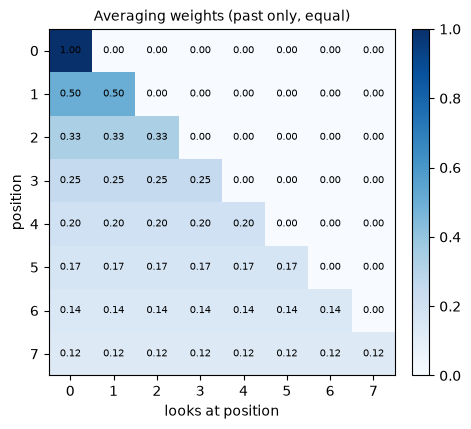

In [36]:
# Visual: the averaging weights. Each row t spreads its weight equally over positions 0..t
import matplotlib.pyplot as plt

def show_matrix(m, title):
    m = m.detach().cpu()
    plt.figure(figsize=(5.5, 4.5))
    plt.imshow(m, cmap="Blues")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            plt.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=7)
    plt.xlabel("looks at position"); plt.ylabel("position"); plt.title(title, fontsize=10); plt.colorbar(fraction=0.046, pad=0.04); plt.show()

show_matrix(wei, "Averaging weights (past only, equal)")

### Version 3: the same again, with softmax
Start from zeros, set the **future** to `-inf`, then softmax. `exp(-inf) = 0`, so the future gets zero weight, and the rest share the weight equally.
**Why bother?** Because now the zeros can be replaced by *learned scores*, so each position can decide how much to care about each past position. That's attention.

In [37]:
# version 3: use Softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
torch.allclose(xbow, xbow3)


False

### Version 4: self-attention, the heart of the Transformer
Every position produces three vectors:
- **Query (Q):** "what am I looking for?"
- **Key (K):** "what do I contain?"
- **Value (V):** "what will I share if you pick me?"

`score = Q · K`: a high score means "this past position is relevant to me". Mask the future, softmax the scores into weights, then take the weighted sum of the values.

This is **Attention Is All You Need**, §3.2.1: `Attention(Q, K, V) = softmax(QKᵀ / √d_k) · V`

In [38]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, 16)
q = query(x) # (B, T, 16)
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T)

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v
#out = wei @ x

out.shape

torch.Size([4, 8, 16])

Row `t` shows how much position `t` attends to each earlier position. Unlike version 3, the weights are **no longer equal**: they depend on the data.

In [39]:
wei[0]

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
        [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
        [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
        [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]],
       grad_fn=<SelectBackward0>)

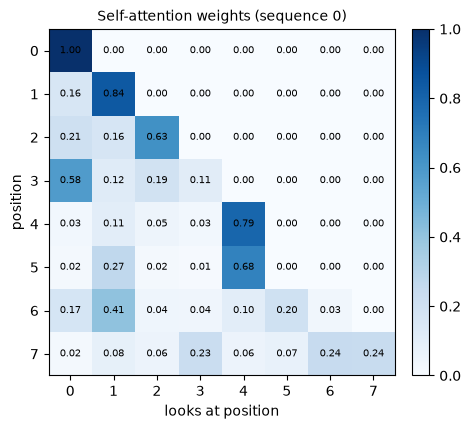

In [40]:
# Visual: real attention weights. Data-dependent, still no peeking at the future
show_matrix(wei[0], "Self-attention weights (sequence 0)")

The upper triangle is all **zero**: the causal mask. Each row still sums to 1, but now some past positions get much more weight than others. Once trained, these weights are where the model decides *which earlier characters matter*.

Notes:
- Attention is a **communication mechanism**. Can be seen as nodes in a directed graph looking at each other and aggregating information with a weighted sum from all nodes that point to them, with data-dependent weights.
- There is no notion of space. Attention simply acts over a set of vectors. This is why we need to positionally encode tokens.
- Each example across batch dimension is of course processed completely independently and never "talk" to each other
- In an "encoder" attention block just delete the single line that does masking with `tril`, allowing all tokens to communicate. This block here is called a "decoder" attention block because it has triangular masking, and is usually used in autoregressive settings, like language modeling.
- "self-attention" just means that the keys and values are produced from the same source as queries. In "cross-attention", the queries still get produced from x, but the keys and values come from some other, external source (e.g. an encoder module)
- "Scaled" attention additional divides `wei` by 1/sqrt(head_size). This makes it so when input Q,K are unit variance, wei will be unit variance too and Softmax will stay diffuse and not saturate too much. Illustration below

### Why divide by √head_size? (the "scaled" in scaled dot-product attention)
Multiplying two random vectors of length 16 gives scores with variance about 16. Big scores make softmax **too sharp**: almost all the weight lands on one position, and learning stalls.
Dividing by √16 = 4 brings the variance back to about 1. Check the three variances below.

In [41]:
k = torch.randn(B,T,head_size)
q = torch.randn(B,T,head_size)
wei = q @ k.transpose(-2, -1) * head_size**-0.5

In [42]:
k.var()

tensor(1.0449)

In [43]:
q.var()

tensor(1.0700)

In [44]:
wei.var()

tensor(1.0918)

### Softmax with small scores → spread out

In [45]:
torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]), dim=-1)

tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])

### The same scores × 8 → sharp, almost "one-hot"
This is what happens without the √d scaling.

In [46]:
torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])*8, dim=-1) # gets too peaky, converges to one-hot

tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])

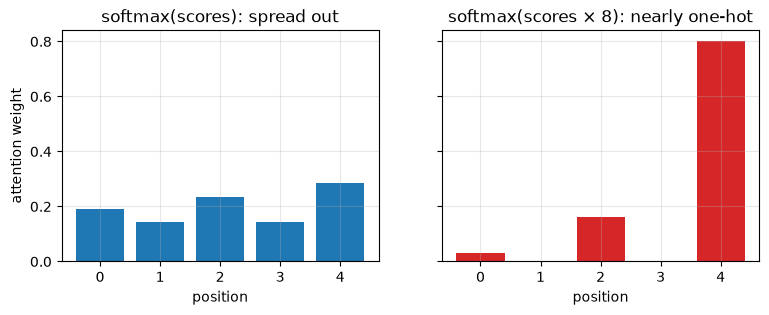

In [47]:
# Visual: why the √d scaling matters
import matplotlib.pyplot as plt

scores = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
fig, ax = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
ax[0].bar(range(5), torch.softmax(scores, -1)); ax[0].set_title("softmax(scores): spread out")
ax[1].bar(range(5), torch.softmax(scores * 8, -1), color="tab:red"); ax[1].set_title("softmax(scores × 8): nearly one-hot")
for a in ax: a.set_xlabel("position"); a.grid(alpha=0.3)
ax[0].set_ylabel("attention weight"); plt.show()

## LayerNorm: keep the numbers in a healthy range
For each token's vector: subtract the mean, divide by the standard deviation, so each row ends up with mean ≈ 0 and std ≈ 1. Then `γ` and `β` let the model rescale if it wants.
Deep networks train much more stably with it.

In [48]:
class LayerNorm1d: # (used to be BatchNorm1d)

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)

  def __call__(self, x):
    # calculate the forward pass
    xmean = x.mean(1, keepdim=True) # batch mean
    xvar = x.var(1, keepdim=True) # batch variance
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

torch.manual_seed(1337)
module = LayerNorm1d(100)
x = torch.randn(32, 100) # batch size 32 of 100-dimensional vectors
x = module(x)
x.shape

torch.Size([32, 100])

In [49]:
x

tensor([[ 0.1335, -0.1059, -0.3824,  ..., -1.3422, -0.1971,  0.8795],
        [-0.0353, -0.7439, -0.3371,  ..., -0.6276, -0.4846,  0.4556],
        [ 0.3069, -1.5010,  1.4898,  ..., -0.6819,  0.9993,  0.8382],
        ...,
        [-1.6080, -1.6324, -0.7634,  ..., -0.9847,  0.0039, -0.8610],
        [-0.2273,  0.0066, -0.2763,  ..., -0.8705, -1.2442, -0.7531],
        [ 0.3054, -0.1505, -0.3809,  ..., -1.4962, -0.7711, -1.0681]])

In [50]:
x[:,0].mean(), x[:,0].std() # mean,std of one feature across all batch inputs

(tensor(0.1469), tensor(0.8803))

In [51]:
x[0,:].mean(), x[0,:].std() # mean,std of a single input from the batch, of its features

(tensor(-9.5367e-09), tensor(1.0000))

### Encoder vs decoder
The original paper translated languages: an **encoder** reads the French sentence (no mask, so every word sees every word), and a **decoder** writes English (masked, so it only sees the past).
**GPT is decoder-only**: it just keeps predicting the next token.

In [52]:
# French to English translation example:

# <--------- ENCODE ------------------><--------------- DECODE ----------------->
# les réseaux de neurones sont géniaux! <START> neural networks are awesome!<END>



## The full GPT: everything put together

This one cell is a complete, trainable GPT. Each piece maps to the paper's Figure 1 (decoder side):

| Code | What it does | Paper |
|---|---|---|
| `token_embedding_table` + `position_embedding_table` | Each character → vector, plus "where am I in the sequence" | §3.4, §3.5 |
| `Head` | One self-attention head (Q, K, V, causal mask, √d scaling) | §3.2.1 |
| `MultiHeadAttention` | Several heads in parallel, each free to track something different | §3.2.2 |
| `FeedFoward` | A small per-token neural network to "think" about what was gathered | §3.3 |
| `Block` | Attention (communicate) → feed-forward (compute), each with **LayerNorm** and a **residual** `x + …` | §3.1 |
| `ln_f` + `lm_head` | Final normalization → scores for every possible next character | §3.4 |

**New in this version:** the training loop records train/val loss in `history`, and the chart below the cell plots it.

In [53]:
import torch
import torch.nn as nn
from torch.nn import functional as F

# hyperparameters
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 32 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0
# ------------

torch.manual_seed(1337)

# wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
        x = tok_emb + pos_emb # (B,T,C)
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

history = {'step': [], 'train': [], 'val': []}  # recorded for the chart below

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        history['step'].append(iter); history['train'].append(losses['train'].item()); history['val'].append(losses['val'].item())

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=2000)[0].tolist()))

0.209729 M parameters


step 0: train loss 4.4116, val loss 4.4022


step 100: train loss 2.6568, val loss 2.6670


step 200: train loss 2.5091, val loss 2.5058


step 300: train loss 2.4196, val loss 2.4336


...

step 4700: train loss 1.6850, val loss 1.8460


step 4800: train loss 1.6660, val loss 1.8415


step 4900: train loss 1.6708, val loss 1.8339


step 4999: train loss 1.6636, val loss 1.8216



And they bridle.

ShALLOUS:
Which thou wast were thrust the gatanss:
Wart If usqual tothys dilth ane away, my fears's wize must off Latcfuldie but my would
As egriededs, I in latist, drove to the vilt.
Good you muselfrind that this me;
But y prunt and plaw yet lets.
In Badiet, and whom the sclittle
Of alind to dry I by wear mysoman,
The shire strook of his butte and thrust for treagint my monte inleous,
To firsh? gry on.

HENRY BOLINGS:
You ardsabed.

EDWARY:
Ithous knear teas repts I crouf to young to too mary.
You contrantymes have myse.-
And fortwerle madany that such swon thee;
Indent my courfessy stoutchs lord
Is as deterp work.

LUCIO:
Aberlioves:
Hed these ortess known, some stingd his refest, as not commpon;
Mest is gon in Racce, movery I want bear
that fravius wrants slevoss make more old lack.

PRAMILLA:
Way, subring.

KING HENRY GAREY:
Ceame,
Second to meine the should e suble will the cliut.

KING ROMENCENTENBRTANGELE:
It do knew you, drawn I long, wout in not Glooding to 

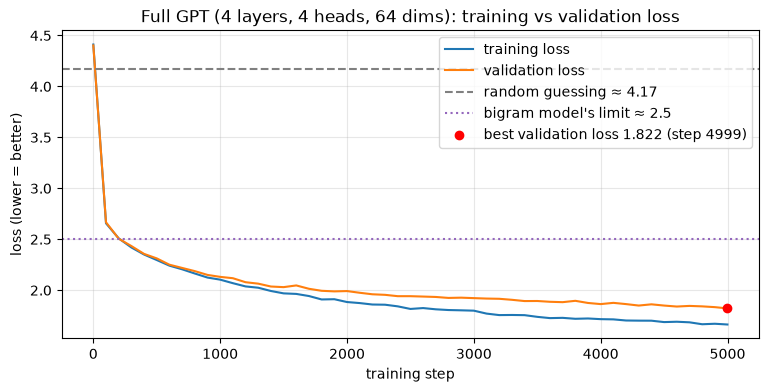

final train 1.664 | final val 1.822 | gap 0.158
growing gap → starting to memorize (overfit); try dropout or more data


In [54]:
# Plot: training vs validation loss for the full GPT
import math
import matplotlib.pyplot as plt

best = min(range(len(history["val"])), key=lambda i: history["val"][i])
plt.figure(figsize=(9, 4))
plt.plot(history["step"], history["train"], label="training loss")
plt.plot(history["step"], history["val"], label="validation loss")
plt.axhline(math.log(vocab_size), ls="--", c="gray", label=f"random guessing ≈ {math.log(vocab_size):.2f}")
plt.axhline(2.5, ls=":", c="tab:purple", label="bigram model's limit ≈ 2.5")
plt.scatter([history["step"][best]], [history["val"][best]], c="red", zorder=3,
            label=f"best validation loss {history['val'][best]:.3f} (step {history['step'][best]})")
plt.xlabel("training step"); plt.ylabel("loss (lower = better)")
plt.title(f"Full GPT ({n_layer} layers, {n_head} heads, {n_embd} dims): training vs validation loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

gap = history["val"][-1] - history["train"][-1]
print(f"final train {history['train'][-1]:.3f} | final val {history['val'][-1]:.3f} | gap {gap:.3f}")
print("small gap → generalizing well" if gap < 0.15 else "growing gap → starting to memorize (overfit); try dropout or more data")

**How to read this chart**
- The GPT breaks through the bigram's ~2.5 limit and keeps improving. That's attention letting each character use its context.
- Watch the **gap** between the curves. When validation stops improving while training keeps falling, the model is starting to memorize. Karpathy's full-size `gpt.py` adds `dropout = 0.2` and reaches about 1.48.

## Try it yourself: an interactive generator
Type a starting prompt and let the trained model continue it.

In [55]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def generate_text(prompt, max_new_tokens=500):
    # Encode the prompt text into token indices
    encoded_prompt = encode(prompt)
    # Convert to a PyTorch tensor and add a batch dimension
    idx = torch.tensor([encoded_prompt], dtype=torch.long, device=device)
    # Generate new tokens using the model
    generated_idx = m.generate(idx, max_new_tokens=max_new_tokens)[0].tolist()
    # Decode the indices back into text
    return decode(generated_idx)

# Design Thinking Patterns: Creating an Empathic, Interactive UI
# Input Field
prompt_input = widgets.Textarea(
    value='ROMEO:',
    placeholder='Type your start prompt here...',
    description='Prompt:',
    disabled=False,
    layout=widgets.Layout(width='90%', height='100px')
)

# Token Slider
tokens_slider = widgets.IntSlider(
    value=200,
    min=50,
    max=1000,
    step=50,
    description='Length:',
    disabled=False,
    orientation='horizontal',
    readout=True,
    readout_format='d'
)

# Action Button
generate_button = widgets.Button(
    description='Generate Text',
    disabled=False,
    button_style='success',
    tooltip='Click to generate text from your prompt',
    icon='magic'
)

# Output Area
output_area = widgets.Output(layout=widgets.Layout(border='1px solid #ddd', padding='10px', margin='10px 0'))

def on_button_clicked(b):
    with output_area:
        clear_output()
        print("Generating... please wait...")
        try:
            res = generate_text(prompt_input.value, max_new_tokens=tokens_slider.value)
            clear_output()
            print(res)
        except Exception as e:
            clear_output()
            print(f"An error occurred during generation: {e}")

generate_button.on_click(on_button_clicked)

# Visual Layout
ui = widgets.VBox([
    widgets.HTML(value="<h3>Shakespeare Text Generator</h3>"),
    prompt_input,
    tokens_slider,
    generate_button,
    widgets.HTML(value="<h4>Generated Output:</h4>"),
    output_area
])

display(ui)

## Save and reload the trained model
Save the weights **and** everything needed to rebuild the model (hyperparameters and the character ↔ ID tables), then load it back.

In [56]:
import torch
import pickle
import os

# ==========================================
# 1. PACKAGING: Saving the Model & Metadata
# ==========================================
def package_model(model, filepath="model_package.pth"):
    package = {
        'model_state_dict': model.state_dict(),
        'hyperparameters': {
            'n_embd': n_embd,
            'n_head': n_head,
            'n_layer': n_layer,
            'block_size': block_size,
            'vocab_size': vocab_size
        },
        'metadata': {
            'stoi': stoi,
            'itos': itos
        }
    }
    torch.save(package, filepath)
    print(f"Model and metadata successfully packaged to: {os.path.abspath(filepath)}")

# Save our currently trained model 'm'
package_model(m, "shakespeare_gpt_v1.pth")

# ==========================================
# 2. DEPLOYMENT: Loading the Packaged Model
# ==========================================
def load_packaged_model(filepath, device='cpu'):
    # Load the package
    package = torch.load(filepath, map_location=device)

    # Extract hyperparameters & metadata
    hp = package['hyperparameters']
    meta = package['metadata']

    # Re-initialize the architecture dynamically (ensure BigramLanguageModel class definition exists)
    loaded_model = BigramLanguageModel()
    loaded_model.load_state_dict(package['model_state_dict'])
    loaded_model.to(device)
    loaded_model.eval()

    print("Model and metadata loaded successfully!")
    return loaded_model, meta['stoi'], meta['itos']

# Test reloading from the package
# loaded_m, loaded_stoi, loaded_itos = load_packaged_model("shakespeare_gpt_v1.pth", device=device)

Model and metadata successfully packaged to: /content/shakespeare_gpt_v1.pth
